# Mod_C
## Week 4

- Statlog Heart Disease Dataset
- Framingham Heart Study Dataset


For Statlog: predict whether heart disease is present using the `target` variable.

For Framingham: predict whether an individual develops coronary heart disease within
10 years using the `TenYearCHD` variable.

The analysis will compare logistic regression models using:

- No feature scaling
- Standardization
- Min-max normalization

Model performance will be evaluated using classification metrics including accuracy, precision, recall,
F1 score, ROC AUC, and confusion matrices.

## Logistic Regression


- Statlog class 1 indicates the presence of heart disease.
- Framingham class 1 indicates development of coronary heart disease within 10 years.

A probability threshold is then used to convert the estimated probability into a predicted class. By default,
a probability of 0.5 or greater is classified as 1.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


In [4]:
heart = pd.read_csv(
    "/content/preprocessed_heart_disease.csv"
)

framingham = pd.read_csv(
    "/content/preprocessed_framingham.csv"
)

print(
    "Heart Disease dataset shape:",
    heart.shape
)

print(
    "Framingham dataset shape:",
    framingham.shape
)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


## Outcome Distribution

Before fitting logistic regression models, the balance of the two outcome classes will be examined.

Class imbalance matters because a model can appear to have high accuracy simply by predicting the majority
class most of the time.

For example, if only a small percentage of patients develop CHD, a model that predicts "no CHD" for nearly
everyone could have high accuracy while still failing to identify the patients who are actually at risk.

In [5]:
print("Statlog target distribution:")
print(
    heart["target"].value_counts()
)

print("\nStatlog target percentages:")
print(
    heart["target"].value_counts(
        normalize=True
    ).round(3)
)

print("\nFramingham TenYearCHD distribution:")
print(
    framingham["TenYearCHD"].value_counts()
)

print("\nFramingham TenYearCHD percentages:")
print(
    framingham["TenYearCHD"].value_counts(
        normalize=True
    ).round(3)
)

Statlog target distribution:
target
0    150
1    120
Name: count, dtype: int64

Statlog target percentages:
target
0    0.556
1    0.444
Name: proportion, dtype: float64

Framingham TenYearCHD distribution:
TenYearCHD
0    3594
1     644
Name: count, dtype: int64

Framingham TenYearCHD percentages:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64


## Predictor Setup

The Statlog dataset contains both continuous measurements and categorical clinical variables.

Continuous variables can be modeled numerically, while categorical variables should not automatically be
treated as if their numerical codes represented continuous quantities. Therefore, categorical Statlog features
will be one-hot encoded.

For Framingham, most variables are already continuous measurements or binary indicators. Education will be
treated as categorical, while the remaining predictors will be treated as numerical or binary features.

The target variables themselves are excluded from the predictors.

In [7]:
# STATLOG

heart_numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

heart_binary_features = [
    "sex",
    "fbs",
    "exang"
]

heart_categorical_features = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
]

heart_features = (
    heart_numeric_features
    + heart_binary_features
    + heart_categorical_features
)


# FRAMINGHAM

framingham_numeric_features = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

framingham_binary_features = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes"
]

framingham_categorical_features = [
    "education"
]

framingham_features = (
    framingham_numeric_features
    + framingham_binary_features
    + framingham_categorical_features
)

print("Statlog predictors:", len(heart_features))
print("Framingham predictors:", len(framingham_features))

Statlog predictors: 13
Framingham predictors: 15


## Train-Test Separation

The datasets will be divided into training and testing sets before scaling or fitting any model.
(so no data leakage).

A stratified split will be used so that the proportion of positive and negative cases remains approximately
the same in the training and testing sets.

The test set will not be used to fit preprocessing transformations, train the models, or select
hyperparameters. It will be used only to evaluate the prespecified modeling approaches on unseen data.

In [8]:

# STATLOG

heart_model_data = heart[
    heart_features + ["target"]
].dropna()

X_heart = heart_model_data[
    heart_features
]

y_heart = heart_model_data[
    "target"
]

X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart,
    y_heart,
    test_size=0.20,
    random_state=42,
    stratify=y_heart
)


# FRAMINGHAM

framingham_model_data = framingham[
    framingham_features + ["TenYearCHD"]
].dropna()

X_framingham = framingham_model_data[
    framingham_features
]

y_framingham = framingham_model_data[
    "TenYearCHD"
]

X_framingham_train, X_framingham_test, y_framingham_train, y_framingham_test = train_test_split(
    X_framingham,
    y_framingham,
    test_size=0.20,
    random_state=42,
    stratify=y_framingham
)

print(
    "Statlog training size:",
    X_heart_train.shape
)

print(
    "Statlog testing size:",
    X_heart_test.shape
)

print(
    "Framingham training size:",
    X_framingham_train.shape
)

print(
    "Framingham testing size:",
    X_framingham_test.shape
)

Statlog training size: (216, 13)
Statlog testing size: (54, 13)
Framingham training size: (3390, 15)
Framingham testing size: (848, 15)


## Feature Scaling

doing 2 approaches:

### standardization

transforms a feature so that it has approximately:

- mean = 0
- standard dev = 1

preserves the general shape of the data while expressing each value relative to the feature's mean and
standard deviation.

### min-max norm:

scaling can be particularly useful when logistic regression uses regularization because the penalty is applied
to model coefficients. Without scaling, variables with very different numerical units may be penalized unevenly.

The scaling in this notebook will be fitted only to the training data through a scikit-learn pipeline to prevent
information from the test set from leaking into model training.

In [9]:
def create_preprocessor(
    numeric_features,
    binary_features,
    categorical_features,
    scaling_method
):

    if scaling_method == "standard":

        numeric_transformer = StandardScaler()

    elif scaling_method == "minmax":

        numeric_transformer = MinMaxScaler()

    elif scaling_method == "none":

        numeric_transformer = "passthrough"

    else:

        raise ValueError(
            "Scaling method must be 'none', 'standard', or 'minmax'."
        )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                numeric_features
            ),
            (
                "binary",
                "passthrough",
                binary_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_features
            )
        ]
    )

    return preprocessor

## Logistic Regression Model Comparison

Three logistic regression pipelines will be compared for each dataset:

1. Logistic regression without numerical feature scaling
2. Logistic regression with standardized numerical features
3. Logistic regression with min-max normalized numerical features

All models use the same train-test split so that differences in performance can be attributed to the modeling
strategy rather than different samples.

The evaluation will include:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Because Framingham contains relatively few positive TenYearCHD cases, recall is especially important. A model
with poor recall may fail to identify many genuinely at-risk patients even if its overall accuracy appears high.

In [10]:
def compare_logistic_scaling(
    X_train,
    X_test,
    y_train,
    y_test,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    results = []

    fitted_models = {}

    for scaling_method in [
        "none",
        "standard",
        "minmax"
    ]:

        preprocessor = create_preprocessor(
            numeric_features,
            binary_features,
            categorical_features,
            scaling_method
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "logistic_regression",
                LogisticRegression(
                    max_iter=5000
                )
            )
        ])

        pipeline.fit(
            X_train,
            y_train
        )

        predictions = pipeline.predict(
            X_test
        )

        probabilities = pipeline.predict_proba(
            X_test
        )[:, 1]

        results.append({
            "Scaling": scaling_method,
            "Accuracy": accuracy_score(
                y_test,
                predictions
            ),
            "Precision": precision_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "ROC AUC": roc_auc_score(
                y_test,
                probabilities
            )
        })

        fitted_models[
            scaling_method
        ] = pipeline

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(dataset_name)
    display(results_df)

    return results_df, fitted_models

### Statlog Logistic Regression

The Statlog models will predict the presence or absence of heart disease.

The same logistic regression model will be tested with no scaling, standardization, and min-max normalization
to determine whether feature scaling changes classification performance.

In [11]:
heart_logistic_results, heart_logistic_models = compare_logistic_scaling(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Scaling,Accuracy,Precision,Recall,F1,ROC AUC
0,none,0.870,0.815,0.917,0.863,0.915
1,standard,0.870,0.815,0.917,0.863,0.914
2,minmax,0.852,0.786,0.917,0.846,0.900


### Framingham Logistic Regression

The Framingham models will predict whether an individual develops coronary heart disease within 10 years.

Because the positive class is less common, the analysis will pay particular attention to recall and F1 score
rather than relying only on accuracy.

In [12]:
framingham_logistic_results, framingham_logistic_models = compare_logistic_scaling(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Scaling,Accuracy,Precision,Recall,F1,ROC AUC
0,none,0.844,0.421,0.062,0.108,0.695
1,standard,0.844,0.421,0.062,0.108,0.695
2,minmax,0.847,0.467,0.054,0.097,0.697


## Confusion Matrices

A confusion matrix separates predictions into four categories:

- True Negative: correctly predicted class 0
- False Positive: predicted class 1 when the true class was 0
- False Negative: predicted class 0 when the true class was 1
- True Positive: correctly predicted class 1

For cardiovascular risk prediction, false negatives are particularly important because they represent patients
who truly belong to the positive class but were missed by the model.

In [13]:
def plot_confusion_matrix_for_model(
    model,
    X_test,
    y_test,
    title
):

    predictions = model.predict(
        X_test
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions
    )

    plt.title(title)
    plt.show()

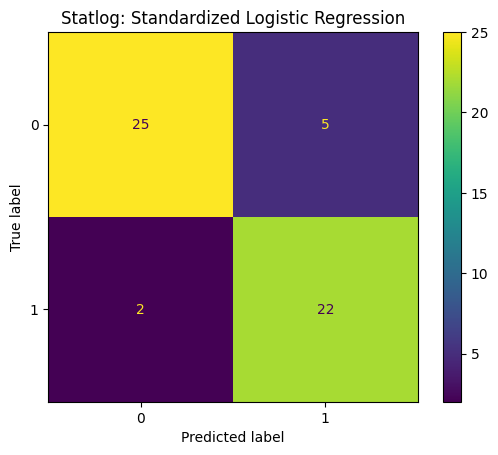

In [14]:
plot_confusion_matrix_for_model(
    heart_logistic_models["standard"],
    X_heart_test,
    y_heart_test,
    "Statlog: Standardized Logistic Regression"
)

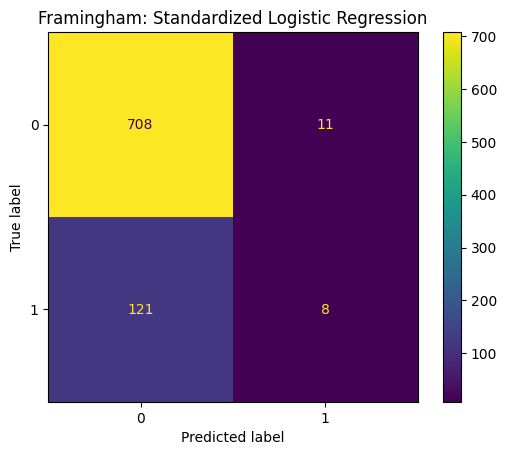

In [15]:
plot_confusion_matrix_for_model(
    framingham_logistic_models["standard"],
    X_framingham_test,
    y_framingham_test,
    "Framingham: Standardized Logistic Regression"
)

## ROC Curves

ROC AUC evaluates how well a model separates the positive and negative classes across many possible probability
thresholds rather than evaluating only the default 0.5 cutoff.

An ROC AUC of:

- 0.5 indicates performance similar to random guessing.
- Values closer to 1 indicate stronger discrimination between the two classes.

ROC AUC is useful when comparing classification models, particularly when class distributions are uneven.

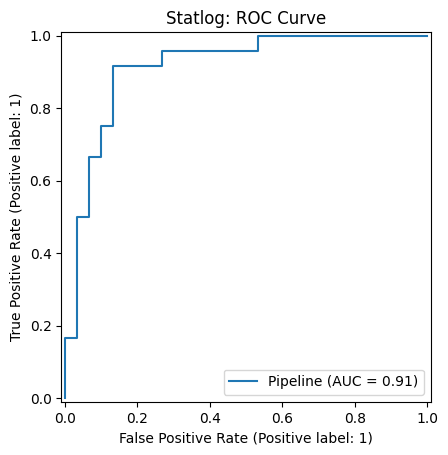

In [16]:
RocCurveDisplay.from_estimator(
    heart_logistic_models["standard"],
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: ROC Curve"
)

plt.show()

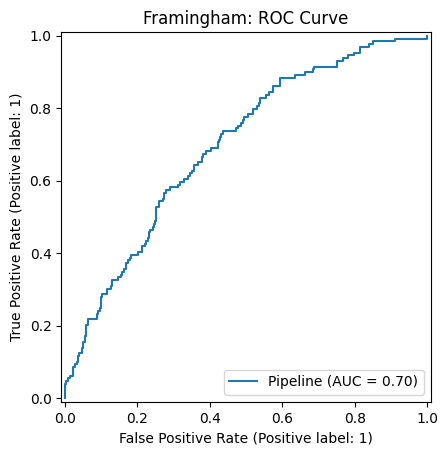

In [17]:
RocCurveDisplay.from_estimator(
    framingham_logistic_models["standard"],
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: ROC Curve"
)

plt.show()

### Statlog Logistic Regression Interpretation

The Statlog outcome is relatively balanced, with approximately 55.6% of observations in class 0
and 44.4% in class 1.

Logistic regression performed strongly on the held-out test set. Both the unscaled and standardized
models achieved an accuracy of 0.870, precision of 0.815, recall of 0.917, and F1 score of 0.863.

The standardized model correctly identified 22 of the 24 positive heart-disease cases and missed only
2 positive cases. Its ROC AUC was approximately 0.914, indicating strong ability to distinguish between
patients with and without heart disease.

Feature scaling produced very little change in performance. Min-max normalization performed slightly
worse, with lower accuracy, F1 score, and ROC AUC.

Therefore, scaling was not necessary to improve predictive performance for Statlog, although
standardization remains useful for placing numerical predictors on comparable scales.

### Framingham Logistic Regression Interpretation

The Framingham outcome is strongly imbalanced. Approximately 84.8% of observations did not develop
coronary heart disease within 10 years, while only 15.2% belonged to the positive class.

The standardized logistic regression model achieved an accuracy of 0.844. However, recall was only
0.062 and F1 score was only 0.108.

The confusion matrix shows why accuracy is misleading in this case. The model correctly classified
708 negative cases but identified only 8 of the 129 positive CHD cases. It missed 121 positive cases.

Despite this poor classification performance at the default probability threshold, ROC AUC was
approximately 0.695. This indicates that the predicted probabilities contain some ability to distinguish
higher-risk from lower-risk patients, even though the default classification strategy performs poorly
for the minority class.

Feature scaling had very little effect on overall performance. The primary modeling problem is therefore
class imbalance rather than feature scale.

## Majority-Class Baseline

Because the Framingham dataset is highly imbalanced, accuracy should be compared with a very simple
baseline model that always predicts the majority class.

If logistic regression cannot meaningfully outperform this baseline, then high accuracy alone should
not be interpreted as evidence of a useful cardiovascular risk model.

In [26]:
def majority_class_baseline(y_train, y_test):

    # Determine the majority class using training data only
    majority_class = y_train.mode()[0]

    # Apply that rule to the unseen test data
    predictions = np.full(
        len(y_test),
        majority_class
    )

    results = {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    }

    return pd.DataFrame(
        [results]
    ).round(3)

In [27]:
print("Statlog Majority-Class Baseline")
display(
    majority_class_baseline(
        y_heart_train,
        y_heart_test
    )
)

print("Framingham Majority-Class Baseline")
display(
    majority_class_baseline(
        y_framingham_train,
        y_framingham_test
    )
)

Statlog Majority-Class Baseline


,Accuracy,Precision,Recall,F1
0,0.556,0.0,0.0,0.0


Framingham Majority-Class Baseline


,Accuracy,Precision,Recall,F1
0,0.848,0.0,0.0,0.0


### Baseline Interpretation

The majority-class comparison confirms that accuracy alone is not an appropriate measure of model
quality for Framingham.

A model that predicts the negative class for every Framingham patient achieves approximately 84.8%
accuracy simply because the dataset contains many more negative than positive cases.

The standard logistic regression model achieved approximately the same overall accuracy while still
having extremely low recall for the positive class.

Therefore, evaluation of this dataset should emphasize metrics such as recall, F1 score, and ROC AUC
rather than accuracy alone.

## Hyperparameter Tuning and Class Imbalance

The initial Framingham model showed very poor recall because positive CHD cases are much less common
than negative cases.

To improve the modeling strategy, logistic regression will be tuned using stratified 5-fold
cross-validation.

Two hyperparameters will be considered:

- `C`: controls regularization strength. Smaller values apply stronger regularization.
- `class_weight`: determines whether the minority and majority classes receive equal importance or
  whether the minority class receives additional weight.

The models will be selected using F1 score because F1 balances precision and recall. This is more
appropriate than accuracy when identifying the positive class is important and the outcome is imbalanced.

Hyperparameter selection will use the training data only. GridSearchCV will not use the test set when
selecting C or class weighting, and the test set will be used afterward to evaluate the selected tuned model.

In [20]:
def tune_logistic_model(
    X_train,
    X_test,
    y_train,
    y_test,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    preprocessor = create_preprocessor(
        numeric_features,
        binary_features,
        categorical_features,
        "standard"
    )

    pipeline = Pipeline([
        (
            "preprocessing",
            preprocessor
        ),
        (
            "logistic_regression",
            LogisticRegression(
                max_iter=5000
            )
        )
    ])

    parameter_grid = {
        "logistic_regression__C": [
            0.01,
            0.1,
            1,
            10,
            100
        ],

        "logistic_regression__class_weight": [
            None,
            "balanced"
        ]
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        pipeline,
        param_grid=parameter_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(
        X_train,
        y_train
    )

    predictions = search.predict(
        X_test
    )

    probabilities = search.predict_proba(
        X_test
    )[:, 1]

    results = pd.DataFrame([{
        "Dataset": dataset_name,

        "Best C": search.best_params_[
            "logistic_regression__C"
        ],

        "Best Class Weight": search.best_params_[
            "logistic_regression__class_weight"
        ],

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }]).round(3)

    print("Best parameters:")
    print(search.best_params_)

    display(results)

    return search, results

### Tuned Statlog Logistic Regression

In [21]:
heart_tuned_model, heart_tuned_results = tune_logistic_model(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog"
)

Best parameters:
{'logistic_regression__C': 1, 'logistic_regression__class_weight': 'balanced'}


,Dataset,Best C,Best Class Weight,Accuracy,Precision,Recall,F1,ROC AUC
0,Statlog,1,balanced,0.87,0.815,0.917,0.863,0.914


### Tuned Framingham Logistic Regression

In [22]:
framingham_tuned_model, framingham_tuned_results = tune_logistic_model(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham"
)

Best parameters:
{'logistic_regression__C': 0.01, 'logistic_regression__class_weight': 'balanced'}


,Dataset,Best C,Best Class Weight,Accuracy,Precision,Recall,F1,ROC AUC
0,Framingham,0.01,balanced,0.667,0.254,0.612,0.359,0.695


## Tuned Model Confusion Matrices

The tuned confusion matrices show how hyperparameter tuning and class weighting change the types of
classification errors made by logistic regression.

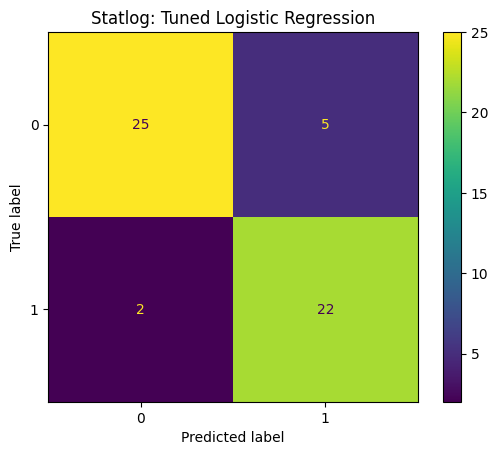

In [23]:
plot_confusion_matrix_for_model(
    heart_tuned_model.best_estimator_,
    X_heart_test,
    y_heart_test,
    "Statlog: Tuned Logistic Regression"
)

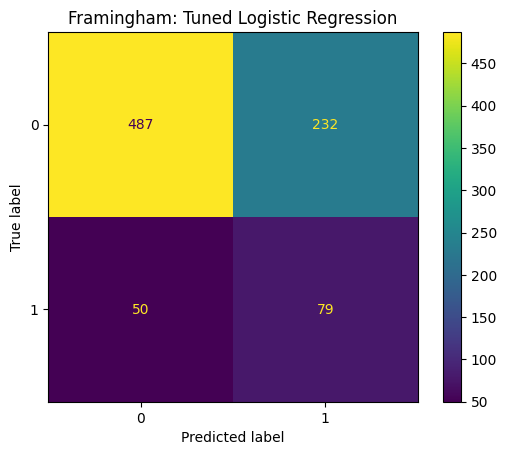

In [24]:
plot_confusion_matrix_for_model(
    framingham_tuned_model.best_estimator_,
    X_framingham_test,
    y_framingham_test,
    "Framingham: Tuned Logistic Regression"
)

## Initial vs Tuned Model Comparison

The following table compares the initial standardized logistic regression models with the final tuned
models.

In [25]:
initial_vs_tuned = pd.DataFrame([

    {
        "Dataset": "Statlog",
        "Model": "Initial Standardized",
        "Accuracy": heart_logistic_results.loc[
            heart_logistic_results["Scaling"] == "standard",
            "Accuracy"
        ].iloc[0],
        "Precision": heart_logistic_results.loc[
            heart_logistic_results["Scaling"] == "standard",
            "Precision"
        ].iloc[0],
        "Recall": heart_logistic_results.loc[
            heart_logistic_results["Scaling"] == "standard",
            "Recall"
        ].iloc[0],
        "F1": heart_logistic_results.loc[
            heart_logistic_results["Scaling"] == "standard",
            "F1"
        ].iloc[0],
        "ROC AUC": heart_logistic_results.loc[
            heart_logistic_results["Scaling"] == "standard",
            "ROC AUC"
        ].iloc[0]
    },

    {
        "Dataset": "Statlog",
        "Model": "Tuned",
        "Accuracy": heart_tuned_results.loc[0, "Accuracy"],
        "Precision": heart_tuned_results.loc[0, "Precision"],
        "Recall": heart_tuned_results.loc[0, "Recall"],
        "F1": heart_tuned_results.loc[0, "F1"],
        "ROC AUC": heart_tuned_results.loc[0, "ROC AUC"]
    },

    {
        "Dataset": "Framingham",
        "Model": "Initial Standardized",
        "Accuracy": framingham_logistic_results.loc[
            framingham_logistic_results["Scaling"] == "standard",
            "Accuracy"
        ].iloc[0],
        "Precision": framingham_logistic_results.loc[
            framingham_logistic_results["Scaling"] == "standard",
            "Precision"
        ].iloc[0],
        "Recall": framingham_logistic_results.loc[
            framingham_logistic_results["Scaling"] == "standard",
            "Recall"
        ].iloc[0],
        "F1": framingham_logistic_results.loc[
            framingham_logistic_results["Scaling"] == "standard",
            "F1"
        ].iloc[0],
        "ROC AUC": framingham_logistic_results.loc[
            framingham_logistic_results["Scaling"] == "standard",
            "ROC AUC"
        ].iloc[0]
    },

    {
        "Dataset": "Framingham",
        "Model": "Tuned",
        "Accuracy": framingham_tuned_results.loc[0, "Accuracy"],
        "Precision": framingham_tuned_results.loc[0, "Precision"],
        "Recall": framingham_tuned_results.loc[0, "Recall"],
        "F1": framingham_tuned_results.loc[0, "F1"],
        "ROC AUC": framingham_tuned_results.loc[0, "ROC AUC"]
    }

]).round(3)

display(initial_vs_tuned)

,Dataset,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Statlog,Initial Standardized,0.870,0.815,0.917,0.863,0.914
1,Statlog,Tuned,0.870,0.815,0.917,0.863,0.914
2,Framingham,Initial Standardized,0.844,0.421,0.062,0.108,0.695
3,Framingham,Tuned,0.667,0.254,0.612,0.359,0.695


### Tuned Statlog Model Interpretation

Cross-validation selected `C = 1` with balanced class weighting for the Statlog logistic regression model.

The tuned model achieved an accuracy of 0.870, precision of 0.815, recall of 0.917, F1 score of
0.863, and ROC AUC of 0.914. These results are essentially identical to the initial standardized
model.

Thats reasonable because the Statlog outcome is already relatively balanced between the two classes.
Additional class weighting therefore provided little benefit.

The model maintained high recall, correctly identifying most patients in the positive heart-disease class,
while also maintaining relatively strong precision.

So the hyperparameter tuning didnt materially improve Statlog performance because the initial logistic
regression strategy was already effective.

### Tuned Framingham Model Interpretation

Cross-validation selected `C = 0.01` with balanced class weighting for the Framingham logistic
regression model.

The tuned model produced a substantial change in classification behavior.

Recall increased from 0.062 in the initial standardized model to 0.612 in the tuned model. F1 score
also increased from 0.108 to 0.359.

This means that the tuned model identified substantially more of the patients who actually developed
coronary heart disease within 10 years.

However, this improvement came with a tradeoff. Accuracy decreased from 0.844 to 0.667, and precision
decreased from 0.421 to 0.254. The balanced model therefore produces more false-positive predictions
while missing far fewer true positive cases.

ROC AUC remained approximately 0.695. Therefore, tuning and class weighting did not substantially
improve the model's overall ability to rank positive cases above negative cases. Instead, the main effect
was to change the model's classification behavior so that the minority positive class received much more
attention.

For a cardiovascular screening context, this tradeoff may be preferable to the initial model because
missing a large majority of genuinely at-risk patients would make the high raw accuracy misleading.

### Tuned Confusion Matrix Interpretation

The Statlog confusion matrix changed very little after tuning, which is consistent with the nearly identical
evaluation metrics.

The Framingham confusion matrix changed substantially. The initial standardized model identified only
8 of the 129 actual positive CHD cases and missed 121, while producing 11 false positives.

After tuning and balanced class weighting, the model identified 79 of the 129 positive cases and missed
only 50. However, false positives increased from 11 to 232.

This demonstrates the tradeoff created by giving greater importance to the minority class. The tuned model
is much more sensitive to patients who develop CHD, but this improved recall comes at the cost of lower
precision and more false-positive predictions.

## Feature Scaling Results

Feature scaling had relatively little effect on predictive performance in either dataset.

For Statlog, the unscaled and standardized models produced identical accuracy, precision, recall, and
F1 scores. Standardization also produced nearly the same ROC AUC as the unscaled model. Min-max
normalization performed slightly worse.

For Framingham, the unscaled and standardized models again produced essentially identical results.
Min-max normalization slightly increased accuracy but reduced recall and F1 score.

Therefore, feature scaling did not materially improve classification accuracy for these datasets.

However, scaling remains useful when logistic regression includes coefficient regularization because it puts
continuous predictors on comparable numerical scales. Standardization was therefore retained in the tuned
models even though it did not independently produce a major performance increase.

## Standardization vs Normalization

Two forms of feature scaling were evaluated.

**Standardization** transforms each numerical predictor relative to its mean and standard deviation, producing
features with approximately mean 0 and standard deviation 1.

**Min-max normalization** rescales each numerical predictor to a range between 0 and 1.

Neither approach changes the meaning of the outcome variable. Instead, they change the numerical scale on
which predictors enter the logistic regression model.

For these datasets, standardization was preferable as the final strategy because it maintained model
performance and works naturally with regularized logistic regression.

## Classification Metrics

Several evaluation metrics were used because no single metric provides a complete description of a
classification model.

- **Accuracy** measures the proportion of all predictions that are correct.
- **Precision** measures the proportion of predicted positive cases that are actually positive.
- **Recall** measures the proportion of actual positive cases that the model successfully identifies.
- **F1 score** balances precision and recall into a single metric.
- **ROC AUC** evaluates how well predicted probabilities separate the positive and negative classes across
  many possible classification thresholds.

The Framingham analysis demonstrates why multiple metrics are necessary. Its initial logistic regression model
had high accuracy because the negative class was very common, but its extremely low recall showed that it
failed to identify most positive CHD cases.

For this reason, recall and F1 score were particularly important when evaluating Framingham.

## Hyperparameter Tuning and Regularization

Logistic regression uses the hyperparameter `C` to control regularization strength.

A smaller value of `C` corresponds to stronger regularization, while a larger value allows the model
coefficients greater freedom.

Five-fold stratified cross-validation was used to compare several values of `C` and whether balanced class
weights should be used.

For Statlog, cross-validation selected `C = 1`, indicating moderate regularization.

For Framingham, cross-validation selected `C = 0.01`, corresponding to substantially stronger regularization,
along with balanced class weighting.

Balanced class weighting increased the importance assigned to the less common positive CHD class during model
training. This substantially increased Framingham recall, although at the cost of lower precision and accuracy.

## Expected and Unexpected Findings

It was expected that logistic regression would be more appropriate than the linear regression approaches used
in previous weeks because the Week 4 outcomes are binary.

Statlog performed strongly, which was consistent with the relatively balanced outcome distribution and the
clinical relationships observed in earlier exploratory analysis.

The most notable finding was the Framingham model's apparently high initial accuracy. At first, an accuracy
above 84% appears strong. However, the majority-class baseline also achieved approximately 84.8% accuracy
while identifying no positive CHD cases.

The initial logistic regression model similarly detected very few positive cases, demonstrating that accuracy
can be misleading when classes are highly imbalanced.

It was also notable that feature scaling had very little effect on classification performance in either dataset.
The more important issue for Framingham was class imbalance rather than differences in predictor scale.

## Relationship to Previous Exploratory Data Analysis

The exploratory analysis completed in Module B helped establish cardiovascular variables that could reasonably
contribute to heart-disease prediction.

Previous Statlog analysis identified relationships involving age, maximum heart rate, exercise-related measures,
blood pressure, cholesterol, and ST depression. Logistic regression allows these clinical measurements to now be
used directly for the project's original binary heart-disease outcome.

Previous Framingham analysis also identified relationships between cardiovascular risk and variables such as age,
blood pressure, BMI, cholesterol, glucose, smoking, and other clinical factors.

Week 4 extends that exploratory work by testing whether these predictors can jointly distinguish individuals who
do and do not develop coronary heart disease within ten years.

The Framingham results also demonstrate that useful exploratory relationships do not guarantee strong binary
classification at a default probability threshold, particularly when the outcome is highly imbalanced.

## Logistic Regression Considerations

Logistic regression assumes that observations provide sufficiently independent examples. The datasets used here
contain patient-level records rather than repeated time-series measurements used directly as separate observations.

Logistic regression can also be affected by multicollinearity and extreme observations. Regularization helps limit
unstable or excessively large coefficients, while feature scaling ensures that numerical predictors measured in
different units are treated more comparably by the regularization penalty.

Categorical Statlog predictors were one-hot encoded rather than treated as continuous numerical quantities so that
the model would not incorrectly assume equal numerical spacing between category codes.

## Optimal Modeling Strategy

The two datasets require different logistic regression strategies.

For Statlog, the classes are relatively balanced and the initial standardized logistic regression model already
performed strongly. Cross-validation selected balanced class weighting, but the tuned model produced identical
held-out performance to the original standardized model. Therefore, balanced weighting offered no practical
improvement on the test set, and the simpler ordinary class-weight setting remains sufficient for this dataset.

For Framingham, the strongly imbalanced outcome makes raw accuracy an inappropriate primary objective. A model
that predicts mostly negative cases can achieve high accuracy while failing to identify patients who develop CHD.

For this dataset, standardized logistic regression with balanced class weights and cross-validated regularization
is the more appropriate strategy when identifying positive CHD cases is important. This substantially improves
recall and F1 score, although the increase in sensitivity comes at the cost of more false positives and lower
overall accuracy.

Therefore, the optimal modeling strategy should be determined not only by the highest numerical score but also
by the class distribution and the practical purpose of the prediction.

# Week 4 Overall Conclusion

Week 4 applied logistic regression and feature scaling to the binary cardiovascular outcomes in the Statlog
Heart Disease and Framingham Heart Study datasets.

Statlog provided a relatively balanced classification problem. The standardized logistic regression model
achieved 0.870 accuracy, 0.917 recall, an F1 score of 0.863, and ROC AUC of approximately 0.914.
Hyperparameter tuning produced essentially identical results, indicating that the initial model was already
effective.

Framingham presented a much more difficult problem because only approximately 15.2% of observations belonged
to the positive TenYearCHD class. The initial standardized model achieved 0.844 accuracy but only 0.062 recall,
meaning it missed most individuals who actually developed CHD. The majority-class baseline demonstrated that
high accuracy was largely driven by class imbalance.

Cross-validated tuning selected stronger regularization and balanced class weighting for Framingham. The tuned
model increased recall from 0.062 to 0.612 and F1 score from 0.108 to 0.359. This improvement came with
lower accuracy and precision because the model generated more false-positive predictions.

Feature scaling itself had little effect on predictive performance in either dataset. However, standardization
remains appropriate when using regularized logistic regression because it places continuous predictors on
comparable scales.

Overall, Week 4 demonstrates that classification performance must be interpreted in the context of the dataset.
Statlog was effectively modeled using standard logistic regression, while Framingham required explicit attention
to class imbalance. The analysis also shows why accuracy should not be considered in isolation when the positive
class is relatively rare.

## AI Use Disclosure

ChatGPT was used as an assistive tool to help organize and articulate formal written interpretations in the markdown cells after the
analysis had been performed and the models had been run. The underlying dataset analysis, model execution,
outputs, and numerical results were generated in the Jupyter Notebook and then interpreted with AI assistance
for clarity and presentation.